# The BNN prior in 1-d: what the PFNs were trained on

**What this is.** `priors.bnn.BNNPrior` (PFNs4BO-style, ported verbatim from pfn-acqpolicy) draws random
functions from deep, sparse tanh networks: depth 8–32, width 32–128, a per-function amplification
(`log_amp_range`) that keeps draws between flat and noise-like, pre-activation and output noise, and
input dimensions that are irrelevant with probability 0.3. Raw outputs are mapped through the ECDF of the
training prior's raw outputs, so y lies in [0, 1] with a roughly uniform marginal. **Every registered
checkpoint was trained on this scale**: build evaluation priors with `checkpoints.make_prior` (which
passes `load_ecdf()`), never with a freshly fitted ECDF.

**How to read this notebook.** Not an experiment: it draws from the prior in the notebook (seeded) to
show what the functions look like, how noise and the ECDF act, and how to use the prior and a
checkpoint together. Settings: `configs/prior/bnn.yaml`.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from omegaconf import OmegaConf

from pfn_repro.checkpoints import load, make_prior
from pfn_repro.utils.env import repo_root

FAMILY = {k: v for k, v in OmegaConf.to_container(OmegaConf.load(
    repo_root() / "src/pfn_repro/configs/prior/bnn.yaml")).items() if k != "name"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FAMILY

{'depth_range': [8, 32],
 'width_range': [32, 128],
 'log_amp_range': [8.0, 20.0],
 'bias_std': 0.1,
 'sparseness': 0.145,
 'preactivation_noise_std_range': [0.0003, 0.0014],
 'output_noise_std_range': [0.0004, 0.0013],
 'frac_relevant_features': 0.7}

## 1. Draws

Twelve noise-free 1-d draws. **What to look for:** a mix of smooth trends, a few local minima and
sharp transitions, and no pure noise (the amplification range is chosen for that).

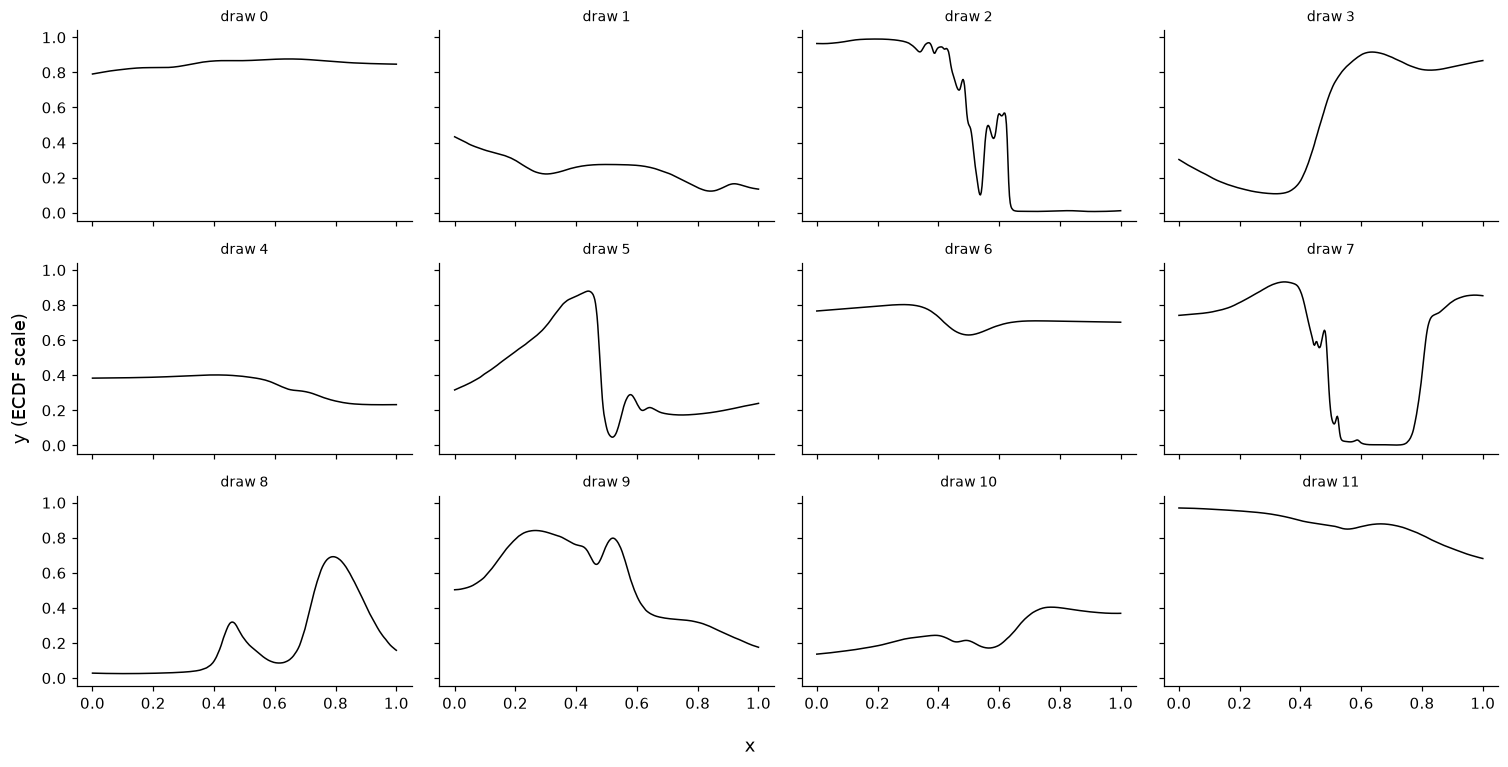

In [ ]:
prior = make_prior(x_dim=1, batch_size=12, seed=0, **FAMILY)
grid = torch.linspace(0, 1, 400)[None, :, None].expand(12, -1, -1)
f = prior.evaluate(grid, noise=False)
fig, axes = plt.subplots(3, 4, figsize=(14, 7), sharex=True, sharey=True)
for b, ax in enumerate(axes.ravel()):
    ax.plot(grid[0, :, 0], f[b], "k", lw=1)
    ax.set_title(f"draw {b}", fontsize=9)
fig.supxlabel("x"); fig.supylabel("y (ECDF scale)"); fig.tight_layout(); plt.show()

## 2. Noise and the y scale

Left: one draw evaluated with and without noise (the noise std is per function, 0.0004–0.0013 on the
output, plus pre-activation noise). Right: the marginal of y over many draws and points, which the ECDF
makes roughly uniform: a PFN never has to learn an unbounded output range.

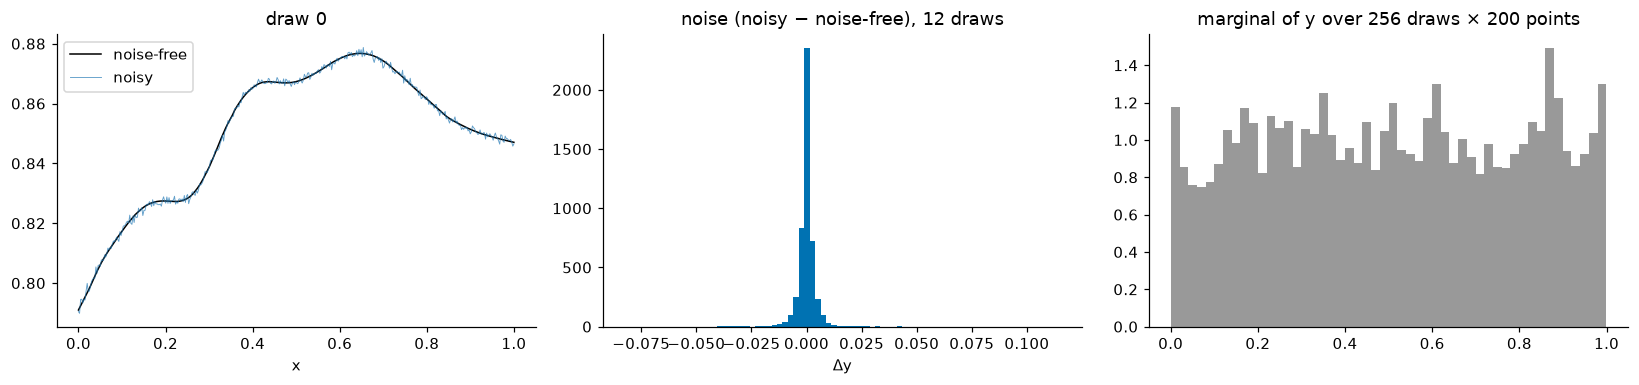

In [ ]:
noisy = prior.evaluate(grid, noise=True)
big = make_prior(x_dim=1, batch_size=256, seed=1, **FAMILY)
ys = big.evaluate(torch.rand(256, 200, 1), noise=False).flatten().numpy()
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].plot(grid[0, :, 0], f[0], "k", lw=1, label="noise-free"); ax[0].plot(grid[0, :, 0], noisy[0], lw=0.6, alpha=0.7, label="noisy")
ax[0].legend(); ax[0].set_title("draw 0")
ax[1].hist((noisy - f).flatten().numpy(), bins=80, color="#0072B2"); ax[1].set_title("noise (noisy − noise-free), 12 draws")
ax[2].hist(ys, bins=50, density=True, color="#999999"); ax[2].set_title("marginal of y over 256 draws × 200 points")
for a in ax[:2]: a.set_xlabel("x" if a is ax[0] else "Δy")
fig.tight_layout(); plt.show()

## 3. Higher dimensions and irrelevant inputs

In d dims each input is relevant with probability 0.7; an irrelevant one has its input weights zeroed,
so f is constant along it. Below: four 2-d draws on a grid, with which dims are relevant.

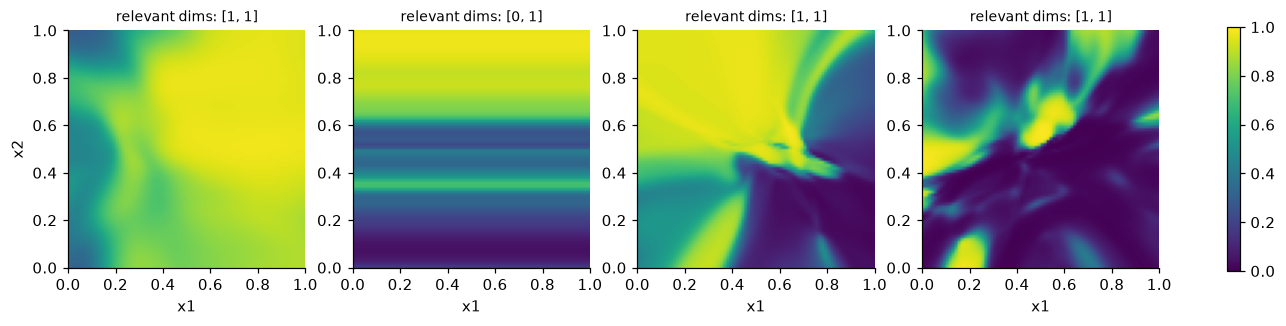

In [ ]:
p2 = make_prior(x_dim=2, batch_size=4, seed=3, **FAMILY)
g = torch.linspace(0, 1, 80)
X = torch.stack(torch.meshgrid(g, g, indexing="ij"), -1).reshape(1, -1, 2).expand(4, -1, -1)
F = p2.evaluate(X, noise=False).reshape(4, 80, 80)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for b, ax in enumerate(axes):
    im = ax.imshow(F[b].T, origin="lower", extent=(0, 1, 0, 1), cmap="viridis", vmin=0, vmax=1)
    ax.set_title(f"relevant dims: {p2.relevant_mask[b].int().tolist()}", fontsize=9); ax.set_xlabel("x1")
axes[0].set_ylabel("x2"); fig.colorbar(im, ax=axes, shrink=0.8); plt.show()

## 4. Usage: episodes, a checkpoint, an acquisition

`sample_episode(n_train, n_test)` returns a context and query points with their noisy y. A surrogate takes
the context and returns bar-distribution logits for the queries; `n_features` must always be passed
(zero-padded inputs without it are mis-scaled). Here the packaged smoke PFN (trained on n ≤ 20) on a
1-d episode, with its PPD density on the bar intervals.

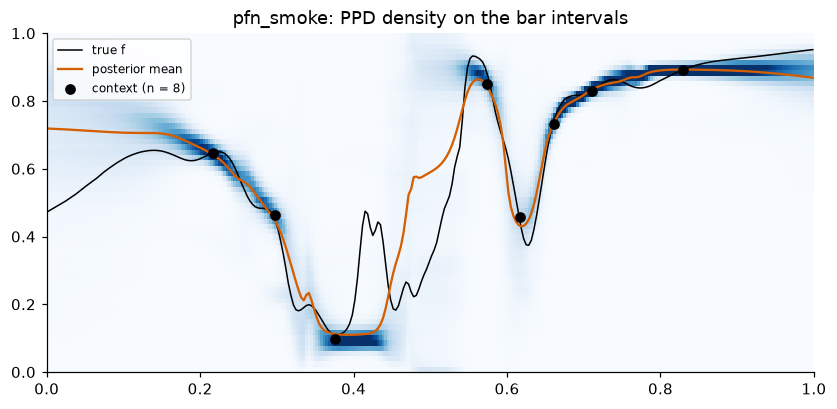

shapes: (1, 8, 1) (1, 8) -> (300, 64)


In [ ]:
pfn, _ = load("pfn_smoke")
ep = make_prior(x_dim=1, batch_size=1, seed=11, **FAMILY)
x_tr, y_tr, _, _ = ep.sample_episode(8, 1)
edges = torch.linspace(0, 1, 301)
xs = ((edges[1:] + edges[:-1]) / 2)[None, :, None]  # cell centres; the heatmap needs edges
with torch.no_grad():
    logits = pfn(x_tr, y_tr, xs, n_features=ep.active_dim)[0]
bd = pfn.bar_dist
density = (torch.softmax(logits, -1) / bd.bucket_widths).numpy()
fig, ax = plt.subplots(figsize=(9, 4))
ax.pcolormesh(edges.numpy(), bd.borders.numpy(), density.T, shading="flat", cmap="Blues", vmax=np.quantile(density, 0.99))
ax.plot(xs[0, :, 0], ep.evaluate(xs, noise=False)[0], "k", lw=1, label="true f")
ax.plot(xs[0, :, 0], bd.mean(logits), color="#D55E00", lw=1.5, label="posterior mean")
ax.scatter(x_tr[0, :, 0], y_tr[0], color="k", zorder=5, label="context (n = 8)")
ax.set_ylim(0, 1); ax.legend(fontsize=8); ax.set_title("pfn_smoke: PPD density on the bar intervals"); plt.show()
print("shapes:", tuple(x_tr.shape), tuple(y_tr.shape), "->", tuple(logits.shape))

**What we see.**
- **Draws.** They range from nearly flat (draws 0, 4, 11 span less than 0.2) through single basins
  (3, 10) to steep, step-like transitions with small wiggles (2, 5, 7). The steep ones put most of the
  range into a narrow x interval, where a surrogate needs dense data.
- **Noise and scale.** Noise is tiny against the y range (most |Δy| < 0.005, with rare outliers to about
  0.04). y fills [0, 1] with a roughly flat marginal.
- **2-d.** An irrelevant dimension shows as stripes (draw 1: only x2 matters). The others mix smooth
  regions with sharp folds.
- **The smoke PFN** (n = 8). Its density collapses onto the context points and widens between them,
  and its mean follows the true function where points are close. Between distant points it
  interpolates: it misses the narrow peak near x = 0.42, where the density shows only faint mass.
  This is the failure mode to expect for an unobserved sharp feature.

To train on this prior: `uv run pfn_repro experiment=train_smoke` (scratch) or a tracked sweep with
`experiment=pfn_large` (the recipe of the registered checkpoint).